# Notebook de documentacion, tratamiento datos y entrenamiento


## Equipo
- Alumno 1 : Lucas Diaz Celauro
- Alumno 2 : Amanda Tardugno

## Configuración

In [1]:
# Bibliotecas, semilla y rutas que se usan en toda la notebook
import re
import sys
import random
import difflib
import unicodedata
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

RUTA_DATOS = Path("data")
RUTA_PINS = RUTA_DATOS / "105_classes_pins_dataset"
RUTA_LFW = RUTA_DATOS / "lfw"
RUTA_PARES = RUTA_DATOS / "raw" / "lfw_pairs"
RUTA_INTERMEDIOS = RUTA_DATOS / "intermedios"
RUTA_INTERMEDIOS.mkdir(parents=True, exist_ok=True)

COLORES = {"Pins": "#1f77b4", "LFW": "#d62728"}

## Inventario

In [2]:
def normalizar_nombre(nombre):
    """Nombre en minúsculas, sin acentos, signos ni guiones bajos, para comparar personas entre datasets."""
    nombre = unicodedata.normalize("NFKD", nombre.replace("_", " ")).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z ]", "", nombre.lower()).strip()

In [3]:
# Una fila por archivo (dataset, persona y ruta), ordenadas por nombre y con "/" para que el orden y las rutas no dependan del sistema operativo
por_nombre = lambda ruta: ruta.name
filas = [
    {"dataset": "Pins", "persona": carpeta.name.removeprefix("pins_"), "ruta": archivo.as_posix()}
    for carpeta in sorted(RUTA_PINS.iterdir(), key=por_nombre) for archivo in sorted(carpeta.iterdir(), key=por_nombre)
]
filas += [
    {"dataset": "LFW", "persona": carpeta.name, "ruta": archivo.as_posix()}
    for carpeta in sorted(RUTA_LFW.iterdir(), key=por_nombre) for archivo in sorted(carpeta.iterdir(), key=por_nombre)
]
imagenes = pd.DataFrame(filas)
imagenes["persona_norm"] = imagenes["persona"].map(normalizar_nombre)
imagenes["extension"] = imagenes["ruta"].str.rsplit(".", n=1).str[-1].str.lower()
imagenes.groupby("dataset", sort=False).agg(personas=("persona", "nunique"), archivos=("ruta", "size"), extensiones=("extension", "unique"))

,personas,archivos,extensiones
dataset,,,
Pins,105,17534,[jpg]
LFW,5749,13233,[jpg]


Pins trae 105 personas y 17.534 fotos; LFW, 5.749 personas y 13.233 fotos. Todos los archivos son `.jpg`.

In [4]:
# Fotos por persona en cada dataset
fotos_por_persona = imagenes.groupby(["dataset", "persona"], sort=False).size().rename("fotos").reset_index()
pd.DataFrame({
    dataset: {"personas": len(f), "mínimo": f.min(), "mediana": f.median(), "media": round(f.mean(), 1), "máximo": f.max()}
    for dataset, f in fotos_por_persona.groupby("dataset", sort=False)["fotos"]
}).T

,personas,mínimo,mediana,media,máximo
Pins,105.0,86.0,169.0,167.0,237.0
LFW,5749.0,1.0,1.0,2.3,530.0


In [5]:
# Personas de LFW agrupadas por cantidad de fotos
fotos_lfw = fotos_por_persona.query("dataset == 'LFW'").set_index("persona")["fotos"]
grupo_lfw = pd.cut(fotos_lfw, bins=[0, 1, 9, 19, np.inf], labels=["1 foto", "2–9", "10–19", "20 o más"])
tabla_grupos = fotos_lfw.groupby(grupo_lfw, observed=True).agg(personas="size", fotos="sum")
tabla_grupos["% de las fotos"] = (100 * tabla_grupos["fotos"] / tabla_grupos["fotos"].sum()).round(1)
tabla_grupos

,personas,fotos,% de las fotos
fotos,,,
1 foto,4069,4069,30.7
2–9,1522,4840,36.6
10–19,96,1301,9.8
20 o más,62,3023,22.8


In [6]:
# Peso de las cinco personas con más fotos en LFW
top_lfw = fotos_lfw.nlargest(5)
print(top_lfw.to_string())
print(f"Suman {top_lfw.sum()} fotos  |  {100 * top_lfw.sum() / fotos_lfw.sum():.1f}% de LFW  |  {100 * top_lfw.sum() / fotos_lfw[fotos_lfw >= 20].sum():.1f}% del grupo con 20 o más")

persona
George_W_Bush        530
Colin_Powell         236
Tony_Blair           144
Donald_Rumsfeld      121
Gerhard_Schroeder    109
Suman 1140 fotos  |  8.6% de LFW  |  37.7% del grupo con 20 o más


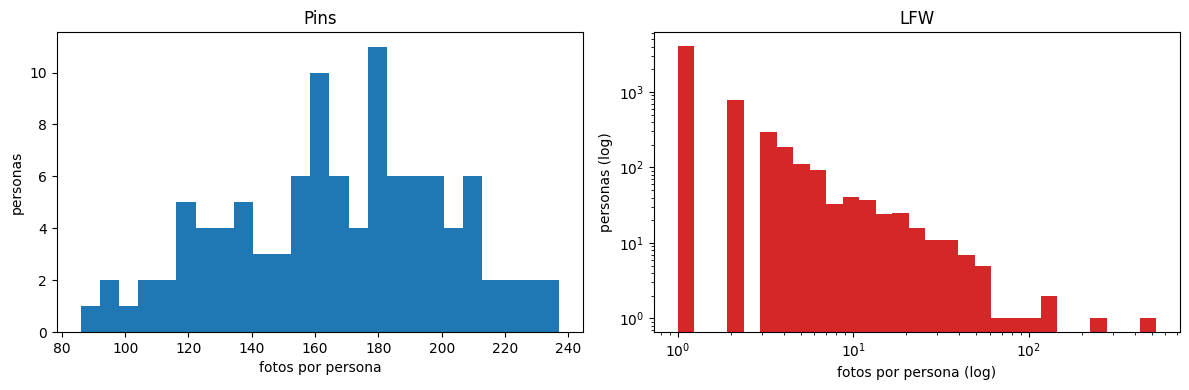

In [7]:
# Distribución de fotos por persona (LFW en escala logarítmica por su cola larga)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
f_pins = fotos_por_persona.query("dataset == 'Pins'")["fotos"]
ejes[0].hist(f_pins, bins=25, color=COLORES["Pins"])
ejes[0].set(title="Pins", xlabel="fotos por persona", ylabel="personas")
ejes[1].hist(fotos_lfw, bins=np.logspace(0, np.log10(fotos_lfw.max() + 1), 30), color=COLORES["LFW"])
ejes[1].set(title="LFW", xlabel="fotos por persona (log)", ylabel="personas (log)", xscale="log", yscale="log")
plt.tight_layout()
plt.show()

*Figura 1. Cantidad de fotos por persona en Pins y en LFW (en LFW, los dos ejes en escala logarítmica).*

Los dos datasets tienen estructuras opuestas (Figura 1). Pins está casi balanceado: cada persona tiene entre 86 y 237 fotos, con una mediana de 169, así que el desbalance de clases no es un problema para entrenar con él. LFW tiene una cola larga: la mediana es de 1 foto por persona, 4.069 personas (el 70,8%) tienen una sola, y las cinco con más fotos suman 1.140, el 37,7% del grupo con 20 o más. George W. Bush tiene 530 fotos.

## Elección de los datasets

El dataset cumple dos funciones con requisitos opuestos. Entrenar la CNN custom necesita **muchas fotos por persona**, porque la red aprende a separar identidades viendo muchas variantes de cada una. Evaluar los modelos necesita **muchas personas que la CNN no vio**, porque ese es el escenario de la app (se registra gente nueva) y porque de ahí sale el umbral que va a `SIMILARITY_THRESHOLD`. Ninguno de los dos datasets cubre ambas cosas por separado:

- Con Pins solo, cada persona que va a evaluación es una menos para entrenar. Con un reparto de 70, 15 y 20 personas, el test tendría 190 combinaciones de personas distintas para los pares negativos, y el umbral saldría de 15 personas.
- Con LFW solo, la CNN entrenaría con 62 personas, y 5 de ellas aportan el 37,7% de las fotos.

Por eso se usan los dos, cada uno para lo que tiene:

| Uso | Dataset |
|---|---|
| Entrenar la CNN y validarla (curvas, early stopping) | Pins: 90 personas sorteadas, con fotos distintas en train y validación |
| Test open-set del mismo dominio que el entrenamiento | Pins: las otras 15 personas |
| Calibrar el umbral, test open-set, desconocidos y pares oficiales | LFW, sin las personas que también están en Pins |

Las 15 personas de test de Pins permiten separar dos causas que, de otro modo, se confunden: si la CNN rinde peor en LFW que en el test de Pins, la diferencia se debe al cambio de dominio y no a que el modelo no generalice a personas nuevas. Que los dos datasets son dominios distintos es, por ahora, una hipótesis que las secciones de formato, resolución e iluminación ponen a prueba.

Los dos pasan por el mismo pipeline de la app (`FaceService`), así que el formato queda unificado en caras alineadas de 112×112. El enunciado ofrece otras opciones: CelebA y CASIA-WebFace son demasiado grandes para procesar en CPU en el tiempo del trabajo, y de FaceScrub, VGGFace2 y DigiFace el propio enunciado advierte que hay que verificar su disponibilidad y su licencia.

Hay una limitación que afecta a cualquier dataset de celebridades: el modelo preentrenado (ArcFace, entrenado con WebFace600K, fotos de famosos tomadas de internet) puede haber visto a algunas de estas personas. Si pasó, el preentrenado tiene una ventaja en la comparación que la CNN no tiene.

## Personas en los dos datasets

In [8]:
# Personas cuyo nombre normalizado está en los dos datasets
nombres = imagenes.groupby("dataset")["persona_norm"].unique()
repetidas_norm = sorted(set(nombres["Pins"]) & set(nombres["LFW"]))
conteo = imagenes[imagenes["persona_norm"].isin(repetidas_norm)].pivot_table(index="persona_norm", columns="dataset", values="ruta", aggfunc="size")
conteo = conteo[["Pins", "LFW"]].rename(columns={"Pins": "fotos en Pins", "LFW": "fotos en LFW"})
print(f"Personas repetidas: {len(conteo)}  |  fotos de LFW afectadas: {conteo['fotos en LFW'].sum()}")
conteo

Personas repetidas: 15  |  fotos de LFW afectadas: 82


dataset,fotos en Pins,fotos en LFW
persona_norm,,
adriana lima,213,1
avril lavigne,162,1
ben affleck,126,7
bill gates,122,17
christian bale,154,1
dwayne johnson,141,2
emma watson,211,5
gwyneth paltrow,187,6
johnny depp,182,2


Quince personas están en los dos datasets, y suman 82 fotos en LFW. Se sacan de LFW y no de Pins: Pins es el único dataset con fotos suficientes para entrenar, y perder 15 de sus 105 personas (el 14,3%) pesa mucho más que perder 82 de las 13.233 fotos de LFW (el 0,62%). Se sacan las 15 aunque alguna caiga en el test de Pins, donde no habría fuga, para que los dos datasets tengan personas disjuntas y las dos evaluaciones sean independientes.

In [9]:
# Coincidencias aproximadas de nombre (ratio >= 0,85) que no son exactas, por si hay variantes de escritura
lfw_norm = list(nombres["LFW"])
aproximadas = [
    {"Pins": nombre, "LFW": candidato, "ratio": round(difflib.SequenceMatcher(None, nombre, candidato).ratio(), 2)}
    for nombre in sorted(nombres["Pins"])
    for candidato in difflib.get_close_matches(nombre, lfw_norm, n=3, cutoff=0.85)
    if candidato != nombre
]
pd.DataFrame(aproximadas)

,Pins,LFW,ratio
0,eliza taylor,elizabeth taylor,0.86
1,elizabeth lail,elizabeth hill,0.86
2,elizabeth olsen,elizabeth dole,0.90
3,richard harmon,richard hamilton,0.87


Las cuatro coincidencias aproximadas son personas distintas que comparten el nombre de pila, así que el cruce exacto alcanza. El cruce por nombre no detecta a una misma persona escrita de dos formas muy distintas (por ejemplo, un apodo). Eso se controla de nuevo con los embeddings, en la verificación de fuga entre conjuntos.

## Integridad, formato y canales

In [10]:
def describir_imagen(ruta):
    """Si la imagen abre, su tamaño, si es gris en la práctica, y su brillo y contraste."""
    img = cv2.imread(ruta)
    if img is None:
        return {"abre": False}
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    canales = img.astype(np.int16)
    dif_canales = max(np.abs(canales[..., 0] - canales[..., 1]).mean(), np.abs(canales[..., 1] - canales[..., 2]).mean())
    return {
        "abre": True, "alto": img.shape[0], "ancho": img.shape[1],
        "es_gris": bool(dif_canales < 2), "brillo": float(gris.mean()), "contraste": float(gris.std()),
    }

In [11]:
# Recorre todos los archivos una sola vez y guarda el resultado en disco, porque leer más de 30.000 fotos tarda
ruta_inventario = RUTA_INTERMEDIOS / "inventario.csv"
if ruta_inventario.exists():
    inventario = pd.read_csv(ruta_inventario)
    assert inventario["ruta"].equals(imagenes["ruta"]), "inventario.csv no corresponde, fila a fila, a los archivos de data/"
else:
    inventario = pd.concat([imagenes, pd.DataFrame([describir_imagen(r) for r in imagenes["ruta"]])], axis=1)
    inventario.to_csv(ruta_inventario, index=False)
inventario.groupby("dataset", sort=False).agg(
    archivos=("ruta", "size"), no_abren=("abre", lambda s: int((~s.astype(bool)).sum())),
    en_gris=("es_gris", "sum"), alto_min=("alto", "min"), alto_max=("alto", "max"), ancho_min=("ancho", "min"), ancho_max=("ancho", "max"),
)

,archivos,no_abren,en_gris,alto_min,alto_max,ancho_min,ancho_max
dataset,,,,,,,
Pins,17534,0,1261,82,802,80,564
LFW,13233,0,45,250,250,250,250


Ningún archivo falla al abrirse. Todos tienen tres canales, pero 1.261 fotos de Pins (el 7,2%) son en la práctica escala de grises (los tres canales iguales), contra 45 en LFW (el 0,3%). Es la primera diferencia de dominio medida: una CNN entrenada con Pins ve fotos en gris con frecuencia, y en LFW casi no aparecen.

## Resoluciones

LFW: tamaños distintos = [[250, 250]]
Pins: lado menor < 112 px: 2626 fotos (15.0%)  |  mediana del lado menor: 175 px


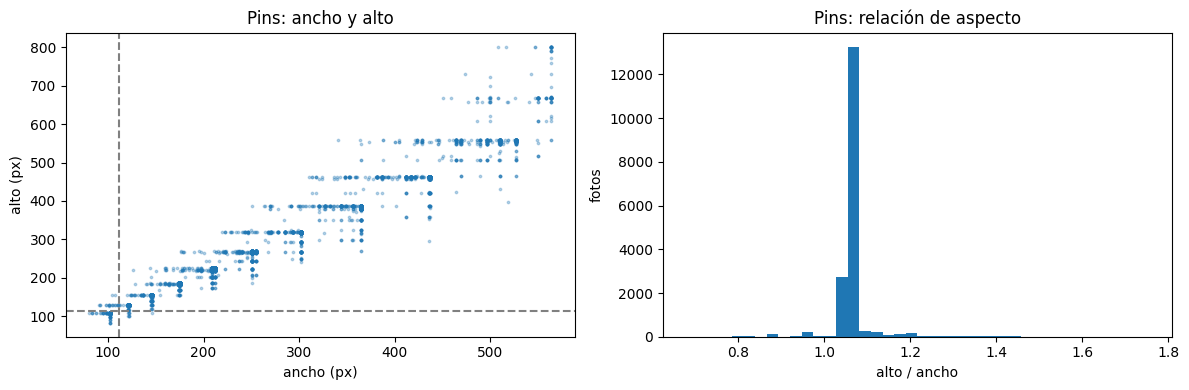

In [12]:
# Tamaño de las fotos de Pins y fotos cuyo lado menor no llega a FACE_SIZE
FACE_SIZE = 112
pins_inv = inventario.query("dataset == 'Pins'")
lado_menor = pins_inv[["alto", "ancho"]].min(axis=1)
print(f"LFW: tamaños distintos = {inventario.query('dataset == \"LFW\"')[['alto', 'ancho']].drop_duplicates().values.tolist()}")
print(f"Pins: lado menor < {FACE_SIZE} px: {(lado_menor < FACE_SIZE).sum()} fotos ({100 * (lado_menor < FACE_SIZE).mean():.1f}%)  |  mediana del lado menor: {lado_menor.median():.0f} px")
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].scatter(pins_inv["ancho"], pins_inv["alto"], s=3, alpha=0.3, color=COLORES["Pins"])
ejes[0].axhline(FACE_SIZE, color="gray", ls="--"); ejes[0].axvline(FACE_SIZE, color="gray", ls="--")
ejes[0].set(title="Pins: ancho y alto", xlabel="ancho (px)", ylabel="alto (px)")
ejes[1].hist(pins_inv["alto"] / pins_inv["ancho"], bins=40, color=COLORES["Pins"])
ejes[1].set(title="Pins: relación de aspecto", xlabel="alto / ancho", ylabel="fotos")
plt.tight_layout()
plt.show()

*Figura 2. Ancho y alto de las fotos de Pins (las líneas marcan 112 px) y su relación de aspecto.*

LFW es homogéneo: todas las fotos miden 250×250. Pins varía entre 80 y 802 px de lado, pero con la relación de aspecto concentrada cerca de 1,07 (Figura 2): son recortes de la cara hechos de antemano, de tamaño variable. El 15,0% (2.626 fotos) tiene el lado menor por debajo de 112 px, así que su cara alineada va a salir de ampliar la imagen. Si eso degrada demasiado la calidad, va a aparecer en el filtro de tamaño mínimo de la cara.

## Iluminación y contraste

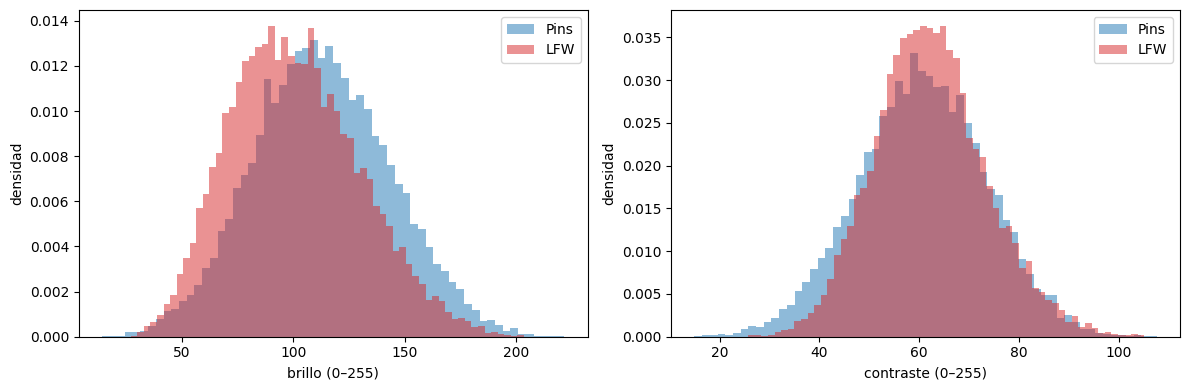

brillo                            contraste                         
           min   25%    50%    75%    max       min   25%   50%   75%    max
dataset                                                                     
Pins      14.0  91.6  112.0  133.9  221.8      15.0  52.1  60.7  69.4  107.6
LFW       27.0  79.5   98.7  120.0  203.6      25.8  54.7  61.8  69.2  105.1

In [13]:
# Brillo (media de gris) y contraste (desvío de gris) por dataset
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, columna in zip(ejes, ["brillo", "contraste"]):
    for dataset in ["Pins", "LFW"]:
        eje.hist(inventario.query("dataset == @dataset")[columna], bins=60, density=True, alpha=0.5, color=COLORES[dataset], label=dataset)
    eje.set(xlabel=f"{columna} (0–255)", ylabel="densidad"); eje.legend()
plt.tight_layout()
plt.show()
inventario.groupby("dataset", sort=False)[["brillo", "contraste"]].describe().loc[:, (slice(None), ["min", "25%", "50%", "75%", "max"])].round(1)

*Figura 3. Brillo y contraste (media y desvío de la imagen en gris) de todas las fotos de cada dataset.*

Pins es más brillante que LFW: la mediana del brillo es 112,0 contra 98,7 (Figura 3). El contraste es parecido (60,7 contra 61,8). Es otra diferencia de dominio, pero moderada: las dos distribuciones se superponen en la mayor parte del rango. Los extremos (brillo mínimo de 14,0 en Pins) se revisan en el control de calidad.

## Muestra visual

In [14]:
def grilla(rutas, filas, columnas, titulos=None, lado=112):
    """Muestra las imágenes en una grilla, redimensionadas a lado × lado."""
    fig, ejes = plt.subplots(filas, columnas, figsize=(columnas * 1.6, filas * 1.75))
    for i, eje in enumerate(np.ravel(ejes)):
        eje.axis("off")
        if i < len(rutas):
            img = rutas[i] if isinstance(rutas[i], np.ndarray) else cv2.imread(str(rutas[i]))
            eje.imshow(cv2.cvtColor(cv2.resize(img, (lado, lado)), cv2.COLOR_BGR2RGB))
            if titulos is not None:
                eje.set_title(titulos[i], fontsize=7)
    plt.tight_layout()
    plt.show()

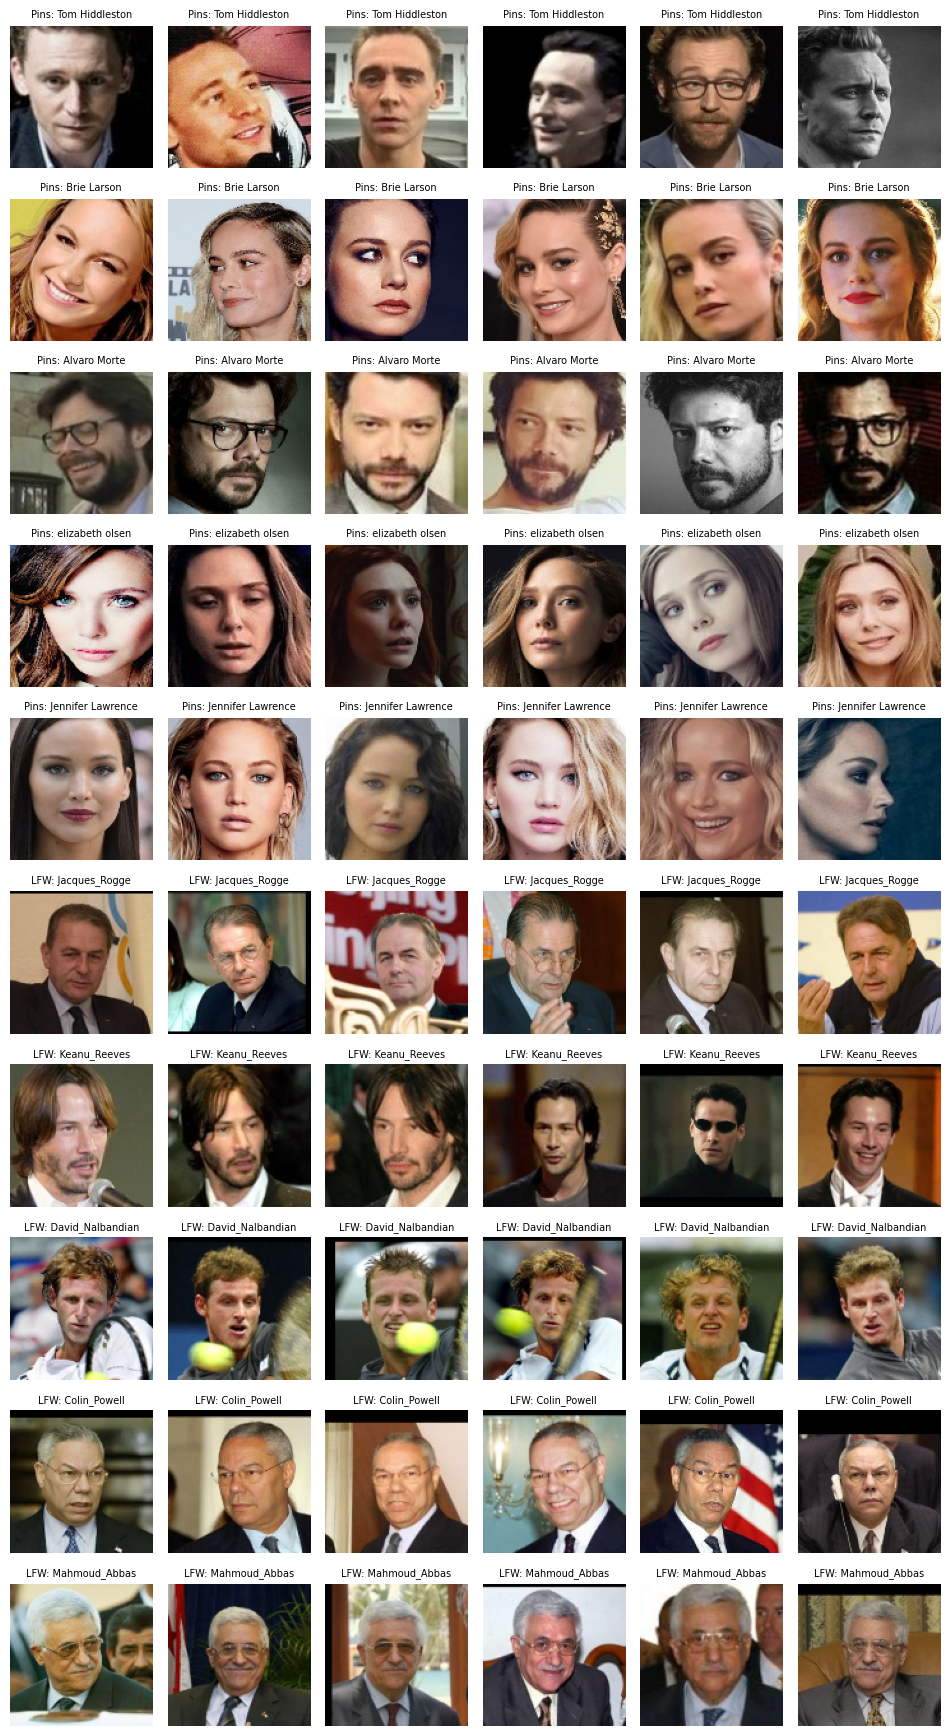

In [15]:
# Seis fotos al azar de cinco personas de cada dataset (en LFW, de las que tienen 10 o más)
rng = random.Random(SEMILLA)
rutas, titulos = [], []
for dataset, candidatas in [("Pins", sorted(fotos_por_persona.query("dataset == 'Pins'")["persona"])), ("LFW", sorted(fotos_lfw[fotos_lfw >= 10].index))]:
    for persona in rng.sample(candidatas, 5):
        fotos = sorted(imagenes.query("dataset == @dataset and persona == @persona")["ruta"])
        for ruta in rng.sample(fotos, 6):
            rutas.append(ruta); titulos.append(f"{dataset}: {persona[:18]}")
grilla(rutas, 10, 6, titulos)

*Figura 4. Seis fotos al azar de cinco personas de Pins (arriba) y de cinco personas de LFW con 10 o más fotos (abajo).*

La Figura 4 muestra la diferencia de dominio más importante, que no se ve en los números anteriores. En Pins la cara ocupa casi toda la foto, con mucha variación de pose (perfiles), expresión, maquillaje e iluminación, y con fotos en gris. En LFW la cara es más chica y está centrada, con mucho contexto: torso, fondo y, a veces, **otras caras** (la primera foto de Mahmoud Abbas). Varias fotos de LFW tienen además bandas negras en los bordes. Las oclusiones aparecen en los dos: anteojos de ver y de sol, una pelota de tenis y manos. Que haya otras caras en las fotos de LFW anticipa el criterio de "más de un rostro" del control de calidad: en LFW, descartar esas fotos perdería imágenes buenas, y lo correcto es quedarse con la cara principal.